<a href="https://colab.research.google.com/github/TamannaSwarna140/Offensive-Slang-Word-Detection/blob/main/Offensive_Or_Slang_Word_Detection_V2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Offensive and Slang Word Detection in Romanised Bengali and English Text

**Author:** Tamanna Akter Swarna

This project classifies short social media words and phrases as offensive/slang or ordinary. It started as a team course project
at Daffodil International University (CSE332); this notebook is a rebuilt version with a stricter evaluation.
The code and analysis are my own; the dataset was collected manually from social media comments by the team, with data collection
support from Mayesha Iqbal, and the original report was written by Tasmima Akter.

> The dataset contains offensive language.

## Summary of results


 **Data:** 3,880 labelled rows, but only 990 unique words and phrases (each repeated about four times): 507 ordinary, 483 offensive/slang.

**Original evaluation:** A random 70/30 split of the 3,880 rows gives about 98% accuracy, but on average 95% of the test rows are exact copies of training rows.

**Corrected evaluation:** After removing duplicates and using 5-fold cross-validation, a word-level model reaches 64.5% accuracy.

**Best approach:** Character n-gram features. Logistic regression reaches 80.0% accuracy and 0.884 ROC-AUC; a linear SVM reaches 81.0% and 0.891 (the two are statistically indistinguishable).

**Chosen model:** Character n-gram logistic regression, because it gives probabilities and inspectable features.

**Held-out check:** 77.3% accuracy on 198 unseen words and phrases.

**Main limitations:** Small dataset, binary context-free labels, and the model partly learns spelling patterns of romanised Bengali versus English.

## 1. Setup

In [4]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay

SEED = 42
np.random.seed(SEED)
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)

## 2. Data

Each row holds a word or short phrase (`Words`) and a label (`label`): 1 for offensive/slang, 0 for ordinary.
The entries are written in English and in romanised Bengali (Bengali written with English letters).
Text is lower-cased and whitespace is normalised before analysis.

In [5]:
DATA_PATH = "data/OffensiveOrSlangWords.csv"
if not os.path.exists(DATA_PATH):
    DATA_PATH = "OffensiveOrSlangWords.csv"   # fallback: file uploaded next to the notebook

df = pd.read_csv(DATA_PATH)
df["text"] = df["Words"].str.lower().str.strip().str.replace(r"\s+", " ", regex=True)
print("Rows:", len(df))
print("Missing values:", int(df.isna().sum().sum()))
print("Label counts:", df["label"].value_counts().to_dict())
df.head()

Rows: 3880
Missing values: 0
Label counts: {1: 1958, 0: 1922}


,Words,label,text
0,Kutta,1,kutta
1,Bodmaish,1,bodmaish
2,Idiot,1,idiot
3,Rubbish,1,rubbish
4,Mair khabi,1,mair khabi


### 2.1 Duplicates
The row count and the number of distinct entries are compared next.

Rows: 3880
Unique words/phrases: 990
Strings with conflicting labels: 0

How often each unique string appears (times: strings):
2     198
4     696
6      48
8      40
10      5
12      2
18      1


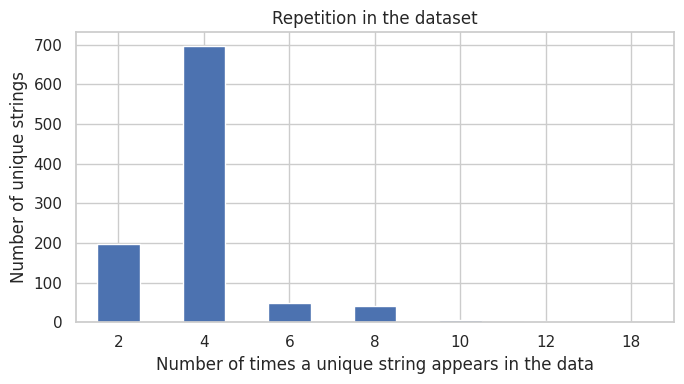

In [6]:
counts = df.groupby("text").size()
labels_per_text = df.groupby("text")["label"].nunique()

print("Rows:", len(df))
print("Unique words/phrases:", df["text"].nunique())
print("Strings with conflicting labels:", int((labels_per_text > 1).sum()))
print("\nHow often each unique string appears (times: strings):")
print(counts.value_counts().sort_index().to_string())

fig, ax = plt.subplots(figsize=(7, 4))
counts.value_counts().sort_index().plot(kind="bar", color="#4C72B0", rot=0, ax=ax)
ax.set_xlabel("Number of times a unique string appears in the data")
ax.set_ylabel("Number of unique strings")
ax.set_title("Repetition in the dataset")
plt.tight_layout()
plt.savefig("images/01_duplicates.png", dpi=150)
plt.show()

**Finding:** The 3,880 rows contain only 990 unique strings. Most appear exactly four times, a few appear more often, and
no string carries conflicting labels. The dataset therefore holds 990 distinct examples, not 3,880. Everything below
works with the de-duplicated set.

In [7]:
data = df.drop_duplicates("text")[["text", "label"]].reset_index(drop=True)
words_per_entry = data["text"].str.split().str.len()

print("Unique examples:", len(data), "| label counts:", data["label"].value_counts().to_dict())
print("Single-word entries: {:.1%}".format((words_per_entry == 1).mean()))
print("Words per entry:", words_per_entry.value_counts().sort_index().to_dict())

Unique examples: 990 | label counts: {0: 507, 1: 483}
Single-word entries: 58.9%
Words per entry: {1: 583, 2: 289, 3: 74, 4: 28, 5: 10, 6: 6}


Of the 990 unique examples, 507 are ordinary and 483 are offensive/slang, so the classes are balanced. 58.9% are single words
and the longest entry has six words.

## 3. Why random splitting on the raw data overstates performance

A random 70/30 split of the 3,880 rows places copies of the same string in both the training and the test set.
A model that has memorised the training strings then scores highly on the test set without learning anything transferable.
The check below repeats the original protocol (word-level features, logistic regression, random 70/30 split) over 20 random splits
and measures how many test rows also appear in the training data.

In [8]:
leaky_acc, overlap = [], []
for s in range(20):
    X_tr, X_te, y_tr, y_te = train_test_split(df["text"], df["label"], test_size=0.30, random_state=s)
    model = Pipeline([("vec", CountVectorizer()), ("clf", LogisticRegression(max_iter=1000))]).fit(X_tr, y_tr)
    leaky_acc.append(accuracy_score(y_te, model.predict(X_te)))
    overlap.append(X_te.isin(set(X_tr)).mean())

print(f"Accuracy, random split of raw rows: mean {np.mean(leaky_acc):.3f} "
      f"(min {np.min(leaky_acc):.3f}, max {np.max(leaky_acc):.3f})")
print(f"Share of test rows that also appear in the training set: {np.mean(overlap):.1%}")

Accuracy, random split of raw rows: mean 0.979 (min 0.968, max 0.988)
Share of test rows that also appear in the training set: 94.9%


**Finding:** The random split gives about 98% accuracy (mean 97.9% over 20 splits), and on average 95% of the test rows are exact
copies of training rows. The score measures memorisation of seen strings. To measure how well a model handles words it
has never seen, the evaluation below uses de-duplicated data, so no test string appears in training.

## 4. Corrected evaluation on unseen words

The 990 unique examples are evaluated with 5-fold stratified cross-validation. Vectorisers sit inside each pipeline, so they are fitted
on the training folds only. Five models are compared:

- **Word-level logistic regression** (bag of words, the original feature approach): baseline.
- **Character n-gram models** (logistic regression, linear SVM, naive Bayes, random forest). Character n-grams break each string into
  short letter sequences (for example "bokachoda" into "bok", "oka", "kac"), so related spellings and word parts share features.

In [9]:
models = {
    "Word-level LR (baseline)": Pipeline([
        ("vec", CountVectorizer()),
        ("clf", LogisticRegression(max_iter=1000))]),
    "Char n-gram LR": Pipeline([
        ("vec", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))),
        ("clf", LogisticRegression(max_iter=1000, C=5))]),
    "Char n-gram linear SVM": Pipeline([
        ("vec", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5))),
        ("clf", LinearSVC(C=1))]),
    "Char n-gram naive Bayes": Pipeline([
        ("vec", CountVectorizer(analyzer="char_wb", ngram_range=(2, 4))),
        ("clf", MultinomialNB())]),
    "Char n-gram random forest": Pipeline([
        ("vec", TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 4))),
        ("clf", RandomForestClassifier(n_estimators=300, random_state=SEED, n_jobs=-1))]),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
rows = []
for name, model in models.items():
    r = cross_validate(model, data["text"], data["label"], cv=cv, scoring=["accuracy", "f1", "roc_auc"])
    rows.append({
        "Model": name,
        "Accuracy": r["test_accuracy"].mean(), "Accuracy std": r["test_accuracy"].std(),
        "F1": r["test_f1"].mean(), "ROC-AUC": r["test_roc_auc"].mean(), "ROC-AUC std": r["test_roc_auc"].std(),
    })
cv_results = pd.DataFrame(rows).set_index("Model").round(3)
display(cv_results)

,Accuracy,Accuracy std,F1,ROC-AUC,ROC-AUC std
Model,,,,,
Word-level LR (baseline),0.645,0.016,0.462,0.687,0.024
Char n-gram LR,0.800,0.020,0.801,0.884,0.015
Char n-gram linear SVM,0.810,0.019,0.810,0.891,0.014
Char n-gram naive Bayes,0.779,0.018,0.790,0.863,0.022
Char n-gram random forest,0.756,0.033,0.752,0.848,0.022


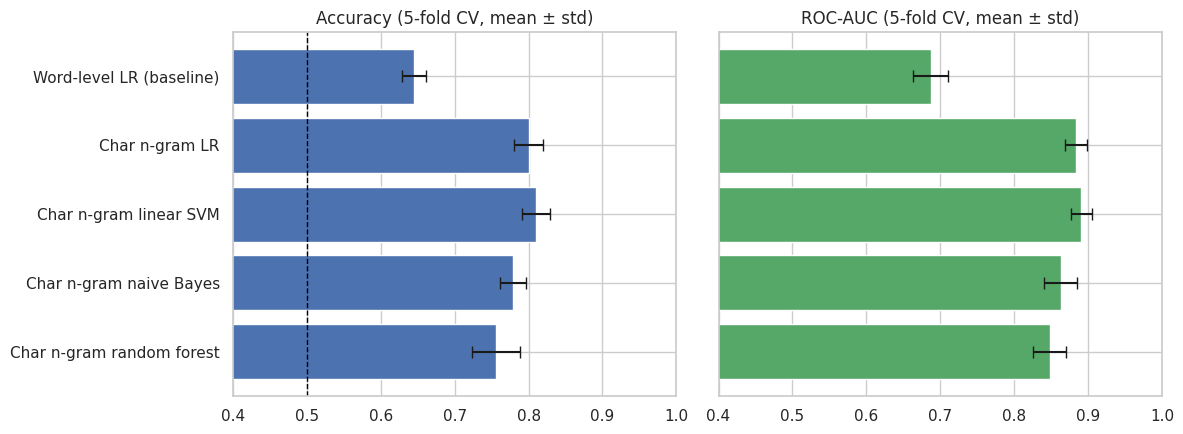

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
order = cv_results.index
axes[0].barh(order, cv_results["Accuracy"], xerr=cv_results["Accuracy std"], color="#4C72B0", capsize=4)
axes[0].set_title("Accuracy (5-fold CV, mean ± std)")
axes[0].axvline(0.5, color="black", linestyle="--", linewidth=1)
axes[0].set_xlim(0.4, 1.0)
axes[1].barh(order, cv_results["ROC-AUC"], xerr=cv_results["ROC-AUC std"], color="#55A868", capsize=4)
axes[1].set_title("ROC-AUC (5-fold CV, mean ± std)")
axes[1].set_xlim(0.4, 1.0)
axes[0].invert_yaxis()   # shared y-axis: inverting once lists the models top to bottom
plt.tight_layout()
plt.savefig("images/02_model_comparison.png", dpi=150)
plt.show()

**Finding:** On unseen words, the word-level baseline reaches 64.5% accuracy (ROC-AUC 0.687, F1 0.46), only modestly above the
50% level of guessing. A word-level model cannot score a word it has not seen, which is why it fails here. Character n-gram features lift performance to about
80%: logistic regression 80.0% (ROC-AUC 0.884), linear SVM 81.0% (0.891), naive Bayes 77.9% (0.863) and random forest 75.6% (0.848).
The logistic regression and SVM results differ by less than the fold-to-fold variation (about 0.02), so they cannot be separated.

**Model choice:** character n-gram logistic regression. It matches the best model within noise, outputs probabilities and exposes
the features it relies on.

## 5. Held-out evaluation of the chosen model

A final check holds out 20% of the unique examples (198 words and phrases), trains on the rest and reports the confusion matrix.

Test strings that also appear in training: 0
                 precision    recall  f1-score   support

       Ordinary      0.764     0.802     0.783       101
Offensive/slang      0.783     0.742     0.762        97

       accuracy                          0.773       198
      macro avg      0.773     0.772     0.772       198
   weighted avg      0.773     0.773     0.772       198



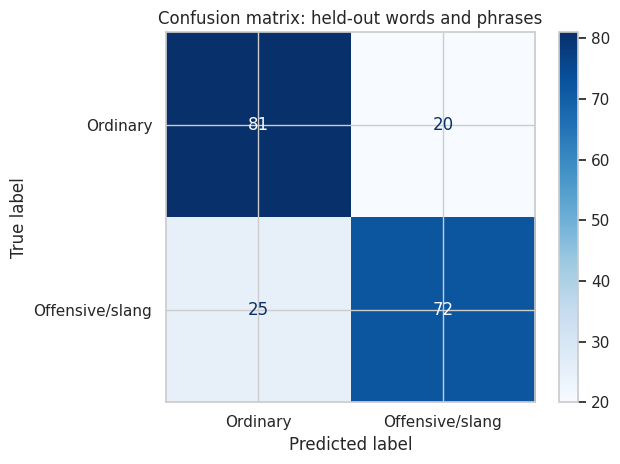

In [11]:
X_tr, X_te, y_tr, y_te = train_test_split(
    data["text"], data["label"], test_size=0.20, stratify=data["label"], random_state=SEED)

best = models["Char n-gram LR"].fit(X_tr, y_tr)
pred = best.predict(X_te)

print("Test strings that also appear in training:", int(X_te.isin(set(X_tr)).sum()))
print(classification_report(y_te, pred, target_names=["Ordinary", "Offensive/slang"], digits=3))

ConfusionMatrixDisplay(confusion_matrix(y_te, pred), display_labels=["Ordinary", "Offensive/slang"]).plot(
    cmap="Blues", values_format="d")
plt.title("Confusion matrix: held-out words and phrases")
plt.tight_layout()
plt.savefig("images/03_confusion_matrix.png", dpi=150)
plt.show()

**Finding:** On 198 unseen strings the model reaches 77.3% accuracy. Precision and recall are balanced: for offensive/slang entries,
precision is 0.78 and recall 0.74; for ordinary entries, precision is 0.76 and recall 0.80. It misses 25 offensive entries and flags 20 ordinary ones.
A single 20% split of this size is noisy, which is why the cross-validated 80% is the better estimate; the two agree within normal variation.

## 6. What the model learned

The largest positive and negative coefficients show which character sequences push the prediction towards each class.

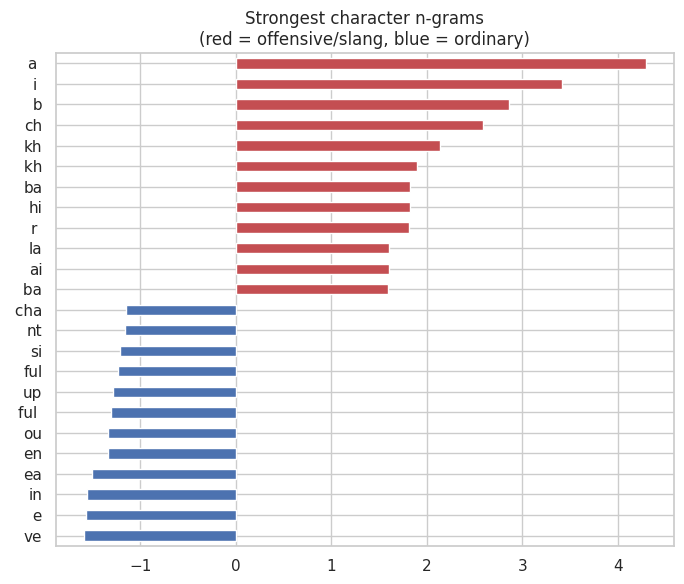

Towards ordinary:  ['ve', ' e', 'in', 'ea', 'en', 'ou', 'ful ', 'up', 'ful', 'si', 'nt', ' cha']
Towards offensive: [' ba', 'ai', 'la', 'r ', 'hi', 'ba', ' kh', 'kh', 'ch', ' b', 'i ', 'a ']


In [12]:
names = best.named_steps["vec"].get_feature_names_out()
coefs = best.named_steps["clf"].coef_[0]
order = np.argsort(coefs)
top = pd.Series(coefs[np.r_[order[:12], order[-12:]]], index=names[np.r_[order[:12], order[-12:]]])

plt.figure(figsize=(7, 6))
top.plot(kind="barh", color=["#4C72B0" if v < 0 else "#C44E52" for v in top])
plt.title("Strongest character n-grams\n(red = offensive/slang, blue = ordinary)")
plt.tight_layout()
plt.savefig("images/04_top_ngrams.png", dpi=150)
plt.show()
print("Towards ordinary: ", list(names[order[:12]]))
print("Towards offensive:", list(names[order[-12:]]))

**Finding:** The strongest features are short letter fragments, not recognisable offensive roots. Letter combinations typical of
English words ("ve", "ea", "ou", "ful") point towards ordinary, and fragments common in romanised Bengali spelling ("kh", "ch", "ba", "la")
point towards offensive.
The model therefore partly learns which language and spelling style an entry uses, and this works because the dataset's
labels correlate with language. It would not transfer reliably to ordinary Bengali words or to English insults.

## 7. Error analysis

In [13]:
errors = pd.DataFrame({"text": X_te.values, "true": y_te.values, "pred": pred})
missed = errors[(errors["true"] == 1) & (errors["pred"] == 0)]["text"].tolist()
flagged = errors[(errors["true"] == 0) & (errors["pred"] == 1)]["text"].tolist()

print(f"Offensive entries missed ({len(missed)}), first 15:\n ", missed[:15])
print(f"\nOrdinary entries flagged ({len(flagged)}), first 15:\n ", flagged[:15])

Offensive entries missed (25), first 15:
  ['call girl', 'vc service', 'goose', 'dope', 'come to my bed', 'scoundrel', 'lesbian', 'asshole', 'public property', 'shameless creature', 'dork', 'jongler production', 'very small', 'horines king', 'cream apa']

Ordinary entries flagged (20), first 15:
  ['shukhobor', 'chal meri vai', 'shocchosachi', 'nikhut', 'meghe vasa bristy', 'mahatvapoorn', 'mehbooba', 'kuch bolo', 'mayabi chokh', 'okaloti kora', 'nazariya', 'hassojjol', 'astagfirullah', 'rockstar', 'mongoljatra']


**Finding:**
- **Missed offensive entries** include English insults (for example "asshole", "scoundrel", "dork") and phrases whose meaning
  depends on context ("come to my bed", "public property"). Short English words carry few offensive character patterns.
- **Wrongly flagged ordinary entries** are mostly romanised Bengali, Hindi or Urdu words with a neutral or positive meaning
  ("mehbooba", "nazariya", "shukhobor"), which the model associates with offensive text through their spelling.
- **Label ambiguity:** some entries could reasonably carry a different label depending on context and intent, and a binary label for a
  context-free word cannot capture that. Some of the errors may be disagreements with the labels rather than model mistakes.

## 8. Conclusions

### Findings
- The raw dataset has 3,880 rows but only 990 unique strings, so a random split inflates accuracy to about 98% through
  memorisation (95% of test rows are exact copies of training rows).
- On unseen words, a word-level model reaches 64.5% accuracy. Character n-gram features reach about 80% (logistic regression 80.0%,
  ROC-AUC 0.884), and the model holds up at 77.3% on a separate held-out set.
- The model partly relies on spelling style (romanised Bengali versus English), and errors cluster in English insults, context-dependent
  phrases and neutral Bengali, Hindi or Urdu words.

### Limitations
- Small dataset (990 unique examples), collected manually; the labelling process and the number of annotators are not documented.
- Single words and short phrases only, with no sentence context, so meaning that depends on context cannot be captured.
- Binary labels for a subjective task, and strong correlation between language and label.
- Performance on real comments, other spelling variants or other platforms is unknown.

### Next steps
- Collect more varied examples, including offensive English words and neutral romanised Bengali words, to break the language-label link.
- Document the labelling guidelines and measure agreement between annotators.
- Move from single words to full comments and test models that use context (for example multilingual transformer models).
- Evaluate on a separate dataset collected from a different source.